# <center>Hybrid Search RAG | Chapter 3: Inverted Index Fundamentals</center>



## Learning flow

```text
WHY
 ↓
ESSENTIAL THEORY
 ↓
DIAGRAM
 ↓
SIMPLE EXAMPLE
 ↓
FROM-SCRATCH CODE
 ↓
PRINT INTERNAL FLOW
 ↓
VISUALIZE
 ↓
SEARCH OPERATIONS
 ↓
PRODUCTION THINKING
 ↓
INTERVIEW + REVISION
```

## You will learn

- Why search engines need indexes
- Forward index
- Inverted index
- Vocabulary
- Posting lists
- Document IDs
- Term Frequency (TF)
- Document Frequency (DF)
- Boolean AND / OR search
- Positional index
- Phrase search
- Tokenization
- Lowercasing
- Stopwords
- Stemming / lemmatization intuition
- Index-time vs query-time
- Why inverted indexes make search fast
- How BM25 depends on inverted indexes
- Inverted index vs vector index

## Core mental model

```text
WITHOUT INDEX

Query
 ↓
Scan D1
Scan D2
Scan D3
...
Scan everything


WITH INVERTED INDEX

Query term
 ↓
Dictionary lookup
 ↓
Posting list
 ↓
Matching documents
```

# 0. How to Study This Notebook

For each section:

1. Read the short theory.
2. Predict the result.
3. Run the code.
4. Read the printed values.
5. Look at the diagram.
6. Answer the checkpoint.

The goal is to understand:

```text
documents
→ tokens
→ vocabulary
→ inverted index
→ posting lists
→ query lookup
→ ranking
```

# 1. Setup

We use only basic Python plus:

- `pandas` for tables
- `numpy` for simple arrays
- `matplotlib` for visual explanations

A **document** is simply a searchable piece of text.

Example:

```text
D1: cat drinks milk
```

In [1]:
import re
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Setup complete.")

Setup complete.


# 2. Why Do We Need an Index?

Suppose we have:

```text
D1: cat drinks milk
D2: dog eats food
D3: cat eats fish
D4: bird eats seeds
```

User searches:

```text
cat
```

A naive approach checks every document.

For 4 documents, this is fine.

For millions of documents, it becomes expensive.

So search engines do extra work **before queries arrive** and create an index.

In [3]:
documents = {
    "D1": "cat drinks milk",
    "D2": "dog eats food",
    "D3": "cat eats fish",
    "D4": "bird eats seeds",
    "D5": "dog drinks water"
}

print("DOCUMENTS")
print("-" * 50)

for doc_id, text in documents.items():
    print(f"{doc_id}: {text}")

DOCUMENTS
--------------------------------------------------
D1: cat drinks milk
D2: dog eats food
D3: cat eats fish
D4: bird eats seeds
D5: dog drinks water


# 3. Naive Search

Naive search:

```text
query
 ↓
open every document
 ↓
check whether term exists
```

Let's implement it with prints so the internal work is visible.

In [4]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())


def naive_search(term, docs):
    print("=" * 70)
    print("NAIVE SEARCH")
    print("=" * 70)

    term = term.lower()
    matches = []

    for doc_id, text in docs.items():
        print(f"\nChecking {doc_id}: {text}")

        tokens = tokenize(text)
        print("Tokens:", tokens)

        if term in tokens:
            print("MATCH")
            matches.append(doc_id)
        else:
            print("No match")

    print("\nFinal matches:", matches)
    return matches


naive_search("cat", documents)

NAIVE SEARCH

Checking D1: cat drinks milk
Tokens: ['cat', 'drinks', 'milk']
MATCH

Checking D2: dog eats food
Tokens: ['dog', 'eats', 'food']
No match

Checking D3: cat eats fish
Tokens: ['cat', 'eats', 'fish']
MATCH

Checking D4: bird eats seeds
Tokens: ['bird', 'eats', 'seeds']
No match

Checking D5: dog drinks water
Tokens: ['dog', 'drinks', 'water']
No match

Final matches: ['D1', 'D3']


['D1', 'D3']

## Problem with naive search

If there are `N` documents, naive search may inspect almost all `N`.

Conceptually:

```text
10 documents      → about 10 checks
1,000 documents   → about 1,000 checks
1,000,000 docs    → about 1,000,000 checks
```

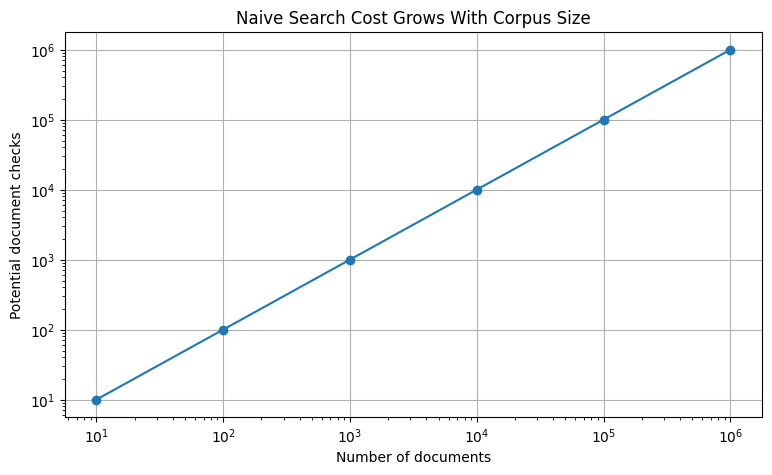

In [5]:
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]

plt.figure(figsize=(9, 5))
plt.plot(sizes, sizes, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of documents")
plt.ylabel("Potential document checks")
plt.title("Naive Search Cost Grows With Corpus Size")
plt.grid(True)
plt.show()

# 4. Forward Index

A **forward index** maps:

```text
document → terms
```

Example:

```text
D1 → cat, drinks, milk
D2 → dog, eats, food
D3 → cat, eats, fish
```

It answers:

> What words are inside this document?

In [11]:
forward_index = {}

for doc_id, text in documents.items():
    forward_index[doc_id] = tokenize(text)

print("FORWARD INDEX: ")
print()

for doc_id, terms in forward_index.items():
    print(f"{doc_id} -> {terms}")

FORWARD INDEX: 

D1 -> ['cat', 'drinks', 'milk']
D2 -> ['dog', 'eats', 'food']
D3 -> ['cat', 'eats', 'fish']
D4 -> ['bird', 'eats', 'seeds']
D5 -> ['dog', 'drinks', 'water']


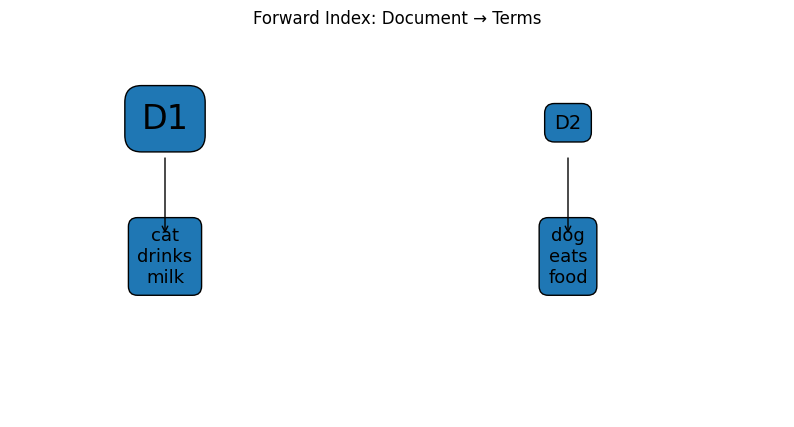

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")

ax.text(0.20, 0.75, "D1", ha="center", fontsize=24,
        bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.20, 0.35, "cat\ndrinks\nmilk", ha="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.5"))
ax.annotate("", xy=(0.20, 0.47), xytext=(0.20, 0.68),
            arrowprops=dict(arrowstyle="->"))

ax.text(0.72, 0.75, "D2", ha="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.72, 0.35, "dog\neats\nfood", ha="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.5"))
ax.annotate("", xy=(0.72, 0.47), xytext=(0.72, 0.68),
            arrowprops=dict(arrowstyle="->"))

plt.title("Forward Index: Document → Terms")
plt.show()

# 5. Inverted Index

Search usually asks the opposite question:

> Which documents contain this term?

So we invert the mapping:

```text
term → documents
```

Example:

```text
cat    → [D1, D3]
dog    → [D2, D5]
drinks → [D1, D5]
eats   → [D2, D3, D4]
```

This structure is the **inverted index**.

In [14]:
def build_inverted_index(docs):
    index = defaultdict(list)

    print("=" * 80)
    print("BUILDING INVERTED INDEX")
    print("=" * 80)

    for doc_id, text in docs.items():
        print(f"\nProcessing {doc_id}")
        print("Raw text:", text)

        tokens = tokenize(text)
        print("Tokens:", tokens)

        unique_tokens = set(tokens)
        print("Unique tokens:", unique_tokens)

        for term in unique_tokens:
            print(f"Adding {doc_id} to posting list for '{term}'")
            index[term].append(doc_id)

    return dict(index)


inverted_index = build_inverted_index(documents)

BUILDING INVERTED INDEX

Processing D1
Raw text: cat drinks milk
Tokens: ['cat', 'drinks', 'milk']
Unique tokens: {'cat', 'milk', 'drinks'}
Adding D1 to posting list for 'cat'
Adding D1 to posting list for 'milk'
Adding D1 to posting list for 'drinks'

Processing D2
Raw text: dog eats food
Tokens: ['dog', 'eats', 'food']
Unique tokens: {'food', 'dog', 'eats'}
Adding D2 to posting list for 'food'
Adding D2 to posting list for 'dog'
Adding D2 to posting list for 'eats'

Processing D3
Raw text: cat eats fish
Tokens: ['cat', 'eats', 'fish']
Unique tokens: {'cat', 'eats', 'fish'}
Adding D3 to posting list for 'cat'
Adding D3 to posting list for 'eats'
Adding D3 to posting list for 'fish'

Processing D4
Raw text: bird eats seeds
Tokens: ['bird', 'eats', 'seeds']
Unique tokens: {'bird', 'seeds', 'eats'}
Adding D4 to posting list for 'bird'
Adding D4 to posting list for 'seeds'
Adding D4 to posting list for 'eats'

Processing D5
Raw text: dog drinks water
Tokens: ['dog', 'drinks', 'water']
Uni

In [16]:
print("FINAL INVERTED INDEX: ")
print()

for term in sorted(inverted_index):
    print(f"{term:<10} -> {inverted_index[term]}")

FINAL INVERTED INDEX: 

bird       -> ['D4']
cat        -> ['D1', 'D3']
dog        -> ['D2', 'D5']
drinks     -> ['D1', 'D5']
eats       -> ['D2', 'D3', 'D4']
fish       -> ['D3']
food       -> ['D2']
milk       -> ['D1']
seeds      -> ['D4']
water      -> ['D5']


# 6. Vocabulary and Posting Lists

### Vocabulary

All unique indexed terms.

### Posting list

The documents associated with one term.

Example:

```text
eats → [D2, D3, D4]
```

Each entry such as `D2` is a **posting**.

In [17]:
vocabulary = sorted(inverted_index.keys())

print("VOCABULARY")
print(vocabulary)

print("\nVocabulary size:")
print(len(vocabulary))

print("\nPosting list for 'eats':")
print(inverted_index["eats"])

VOCABULARY
['bird', 'cat', 'dog', 'drinks', 'eats', 'fish', 'food', 'milk', 'seeds', 'water']

Vocabulary size:
10

Posting list for 'eats':
['D2', 'D3', 'D4']


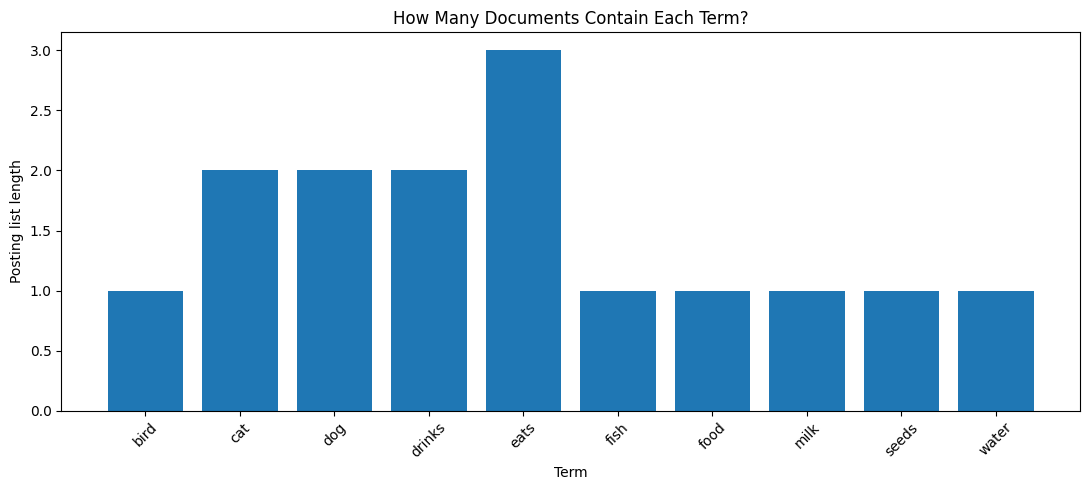

In [18]:
terms = sorted(inverted_index)
lengths = [len(inverted_index[t]) for t in terms]

plt.figure(figsize=(11, 5))
plt.bar(terms, lengths)
plt.xticks(rotation=45)
plt.ylabel("Posting list length")
plt.xlabel("Term")
plt.title("How Many Documents Contain Each Term?")
plt.tight_layout()
plt.show()

# 7. Indexed Search

Instead of scanning every document, we do:

```text
query = cat
 ↓
index["cat"]
 ↓
[D1, D3]
```

In [19]:
def indexed_search(term, index):
    normalized = term.lower()

    print("=" * 70)
    print("INDEX LOOKUP")
    print("=" * 70)

    print("\nOriginal query:", term)
    print("Normalized query:", normalized)

    results = index.get(normalized, [])

    print("\nPosting list:")
    #print(results)

    return results


indexed_search("cat", inverted_index)

INDEX LOOKUP

Original query: cat
Normalized query: cat

Posting list:


['D1', 'D3']

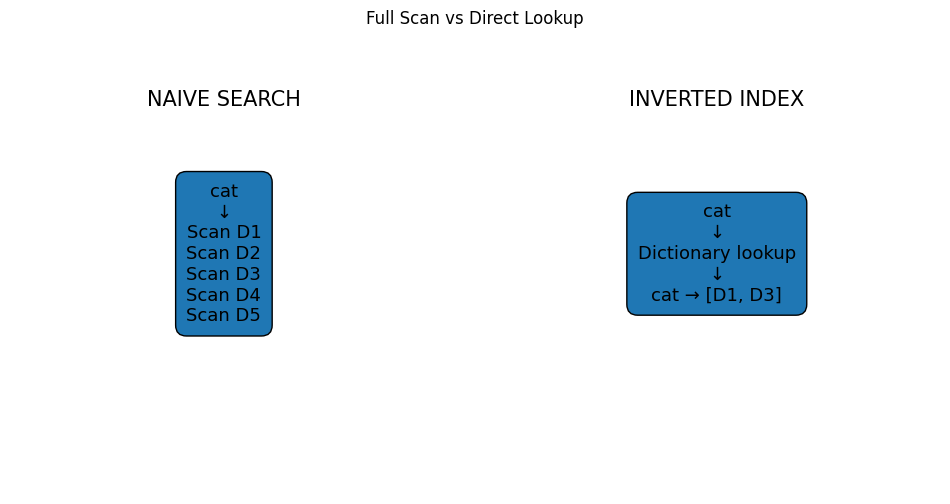

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

ax.text(0.23, 0.84, "NAIVE SEARCH", ha="center", fontsize=15)
ax.text(
    0.23, 0.52,
    "cat\n↓\nScan D1\nScan D2\nScan D3\nScan D4\nScan D5",
    ha="center", va="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.text(0.76, 0.84, "INVERTED INDEX", ha="center", fontsize=15)
ax.text(
    0.76, 0.52,
    "cat\n↓\nDictionary lookup\n↓\ncat → [D1, D3]",
    ha="center", va="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.6")
)

plt.title("Full Scan vs Direct Lookup")
plt.show()

# CHECKPOINT 1

Explain:

1. What is a forward index?
2. What is an inverted index?
3. What is a vocabulary?
4. What is a posting list?
5. Why is an inverted index faster than scanning every document?

# 8. Document Frequency (DF)

Document Frequency means:

> In how many documents does this term occur?

Example:

```text
eats → [D2, D3, D4]

DF(eats) = 3
```

This tells us whether a term is common or rare.

In [21]:
document_frequency = {
    term: len(postings)
    for term, postings in inverted_index.items()
}

print("DOCUMENT FREQUENCY")
print("=" * 50)

for term in sorted(document_frequency):
    print(f"{term:<10} DF={document_frequency[term]}")

DOCUMENT FREQUENCY
bird       DF=1
cat        DF=2
dog        DF=2
drinks     DF=2
eats       DF=3
fish       DF=1
food       DF=1
milk       DF=1
seeds      DF=1
water      DF=1


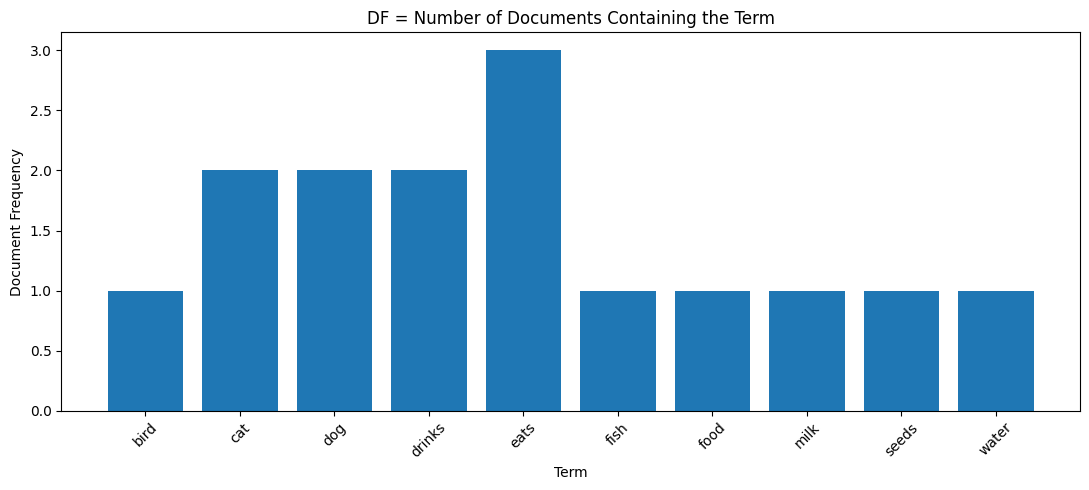

In [22]:
terms = sorted(document_frequency)
dfs = [document_frequency[t] for t in terms]

plt.figure(figsize=(11, 5))
plt.bar(terms, dfs)
plt.xticks(rotation=45)
plt.ylabel("Document Frequency")
plt.xlabel("Term")
plt.title("DF = Number of Documents Containing the Term")
plt.tight_layout()
plt.show()

## Why DF matters

If a word appears in almost every document, it is not very distinctive.

If it appears in only one or two documents, it may be very useful.

This leads later to:

```text
IDF = Inverse Document Frequency
```

# 9. Term Frequency (TF)

Term Frequency means:

> How many times does a term appear inside one document?

Example:

```text
D1: cat cat cat drinks milk

TF(cat, D1) = 3
```

In [23]:
repeated_docs = {
    "D1": "cat cat cat drinks milk",
    "D2": "cat drinks water",
    "D3": "dog eats food"
}

for doc_id, text in repeated_docs.items():
    print(f"{doc_id}: {text}")

D1: cat cat cat drinks milk
D2: cat drinks water
D3: dog eats food


In [24]:
def show_term_frequency(term, text):
    tokens = tokenize(text)
    counts = Counter(tokens)

    print("Text:", text)
    print("Tokens:", tokens)
    print("Counts:", counts)
    print(f"TF('{term}') =", counts[term.lower()])

    return counts[term.lower()]


show_term_frequency(
    "cat",
    repeated_docs["D1"]
)

Text: cat cat cat drinks milk
Tokens: ['cat', 'cat', 'cat', 'drinks', 'milk']
Counts: Counter({'cat': 3, 'drinks': 1, 'milk': 1})
TF('cat') = 3


3

# 10. Rich Posting Lists

Real posting lists can store more than a document ID.

For example:

```text
cat →
[
  {doc_id: D1, tf: 3},
  {doc_id: D2, tf: 1}
]
```

This information becomes useful for ranking.

In [25]:
def build_tf_index(docs):
    index = defaultdict(list)

    for doc_id, text in docs.items():
        counts = Counter(tokenize(text))

        print(f"\n{doc_id}")
        print("Counts:", counts)

        for term, tf in counts.items():
            posting = {
                "doc_id": doc_id,
                "tf": tf
            }

            print(f"{term} -> {posting}")
            index[term].append(posting)

    return dict(index)


tf_index = build_tf_index(repeated_docs)


D1
Counts: Counter({'cat': 3, 'drinks': 1, 'milk': 1})
cat -> {'doc_id': 'D1', 'tf': 3}
drinks -> {'doc_id': 'D1', 'tf': 1}
milk -> {'doc_id': 'D1', 'tf': 1}

D2
Counts: Counter({'cat': 1, 'drinks': 1, 'water': 1})
cat -> {'doc_id': 'D2', 'tf': 1}
drinks -> {'doc_id': 'D2', 'tf': 1}
water -> {'doc_id': 'D2', 'tf': 1}

D3
Counts: Counter({'dog': 1, 'eats': 1, 'food': 1})
dog -> {'doc_id': 'D3', 'tf': 1}
eats -> {'doc_id': 'D3', 'tf': 1}
food -> {'doc_id': 'D3', 'tf': 1}


In [29]:
print("TF-AWARE INDEX: ")
print()

for term in sorted(tf_index):
    print(f"{term:<10} -> {tf_index[term]}")

TF-AWARE INDEX: 

cat        -> [{'doc_id': 'D1', 'tf': 3}, {'doc_id': 'D2', 'tf': 1}]
dog        -> [{'doc_id': 'D3', 'tf': 1}]
drinks     -> [{'doc_id': 'D1', 'tf': 1}, {'doc_id': 'D2', 'tf': 1}]
eats       -> [{'doc_id': 'D3', 'tf': 1}]
food       -> [{'doc_id': 'D3', 'tf': 1}]
milk       -> [{'doc_id': 'D1', 'tf': 1}]
water      -> [{'doc_id': 'D2', 'tf': 1}]


# 11. Boolean Search

Posting lists make Boolean search easy.

### AND

```text
cat AND eats
```

means both terms must occur.

### OR

```text
cat OR dog
```

means at least one must occur.

In [30]:
def boolean_and(term1, term2, index):
    p1 = set(index.get(term1.lower(), []))
    p2 = set(index.get(term2.lower(), []))

    print(term1, "->", p1)
    print(term2, "->", p2)

    result = p1.intersection(p2)

    print("\nAND result:")
    print(result)

    return sorted(result)


boolean_and("cat", "eats", inverted_index)

cat -> {'D1', 'D3'}
eats -> {'D4', 'D2', 'D3'}

AND result:
{'D3'}


['D3']

In [31]:
def boolean_or(term1, term2, index):
    p1 = set(index.get(term1.lower(), []))
    p2 = set(index.get(term2.lower(), []))

    print(term1, "->", p1)
    print(term2, "->", p2)

    result = p1.union(p2)

    print("\nOR result:")
    #print(result)

    return sorted(result)


boolean_or("cat", "dog", inverted_index)

cat -> {'D1', 'D3'}
dog -> {'D2', 'D5'}

OR result:


['D1', 'D2', 'D3', 'D5']

# 12. Multi-Term AND Search

For:

```text
cat eats fish
```

we intersect all three posting lists.

In [32]:
def multi_and(query, index):
    terms = tokenize(query)

    print("Query terms:", terms)

    posting_sets = []

    for term in terms:
        postings = set(index.get(term, []))
        print(f"{term} -> {postings}")
        posting_sets.append(postings)

    if not posting_sets:
        return []

    result = posting_sets[0]

    for postings in posting_sets[1:]:
        result = result.intersection(postings)
        print("Running intersection:", result)

    return sorted(result)


multi_and(
    "cat eats fish",
    inverted_index
)

Query terms: ['cat', 'eats', 'fish']
cat -> {'D1', 'D3'}
eats -> {'D4', 'D2', 'D3'}
fish -> {'D3'}
Running intersection: {'D3'}
Running intersection: {'D3'}


['D3']

# CHECKPOINT 2

Explain:

1. Difference between TF and DF.
2. What `cat AND eats` means.
3. What `cat OR dog` means.
4. Why richer postings store TF.
5. Why Boolean operations fit naturally with posting lists.

# 13. Positional Index

A normal inverted index can say:

```text
red appears in D1
apple appears in D1
```

But it cannot tell whether:

```text
red apple
```

appears as an exact phrase.

For phrase search we need token positions.

In [33]:
position_docs = {
    "D1": "red apple tastes good",
    "D2": "green apple tastes good",
    "D3": "red car moves fast",
    "D4": "I like red sweet apple"
}

for doc_id, text in position_docs.items():
    print(f"{doc_id}: {text}")

D1: red apple tastes good
D2: green apple tastes good
D3: red car moves fast
D4: I like red sweet apple


In [35]:
def build_positional_index(docs):
    index = defaultdict(lambda: defaultdict(list))

    for doc_id, text in docs.items():
        tokens = tokenize(text)

        print(f"\n{doc_id}")
        print("Tokens:", tokens)
        print()

        for pos, term in enumerate(tokens):
            index[term][doc_id].append(pos)

            print(
                f"term={term:<8} "
                f"doc={doc_id} "
                f"position={pos}"
            )

    return {
        term: dict(doc_map)
        for term, doc_map in index.items()
    }


positional_index = build_positional_index(
    position_docs
)


D1
Tokens: ['red', 'apple', 'tastes', 'good']

term=red      doc=D1 position=0
term=apple    doc=D1 position=1
term=tastes   doc=D1 position=2
term=good     doc=D1 position=3

D2
Tokens: ['green', 'apple', 'tastes', 'good']

term=green    doc=D2 position=0
term=apple    doc=D2 position=1
term=tastes   doc=D2 position=2
term=good     doc=D2 position=3

D3
Tokens: ['red', 'car', 'moves', 'fast']

term=red      doc=D3 position=0
term=car      doc=D3 position=1
term=moves    doc=D3 position=2
term=fast     doc=D3 position=3

D4
Tokens: ['i', 'like', 'red', 'sweet', 'apple']

term=i        doc=D4 position=0
term=like     doc=D4 position=1
term=red      doc=D4 position=2
term=sweet    doc=D4 position=3
term=apple    doc=D4 position=4


In [37]:
print("POSITIONAL INDEX:")
print("")

for term in sorted(positional_index):
    print(
        f"{term:<10} -> "
        f"{positional_index[term]}"
    )

POSITIONAL INDEX:

apple      -> {'D1': [1], 'D2': [1], 'D4': [4]}
car        -> {'D3': [1]}
fast       -> {'D3': [3]}
good       -> {'D1': [3], 'D2': [3]}
green      -> {'D2': [0]}
i          -> {'D4': [0]}
like       -> {'D4': [1]}
moves      -> {'D3': [2]}
red        -> {'D1': [0], 'D3': [0], 'D4': [2]}
sweet      -> {'D4': [3]}
tastes     -> {'D1': [2], 'D2': [2]}


# 14. Exact Phrase Search

For:

```text
red apple
```

we need:

```text
red at position p
apple at position p + 1
```

in the same document.

In [38]:
def phrase_search_two_words(
    word1,
    word2,
    index
):
    docs1 = index.get(word1.lower(), {})
    docs2 = index.get(word2.lower(), {})

    print(word1, "->", docs1)
    print(word2, "->", docs2)

    common_docs = (
        set(docs1)
        .intersection(docs2)
    )

    print("\nCommon documents:")
    print(common_docs)

    matches = []

    for doc_id in sorted(common_docs):
        positions1 = docs1[doc_id]
        positions2 = docs2[doc_id]

        print(f"\nChecking {doc_id}")
        print(word1, "positions:", positions1)
        print(word2, "positions:", positions2)

        for p in positions1:
            expected = p + 1

            print(
                f"If '{word1}' is at {p}, "
                f"'{word2}' must be at {expected}"
            )

            if expected in positions2:
                print("PHRASE MATCH")
                matches.append(doc_id)
                break

    return matches


phrase_search_two_words(
    "red",
    "apple",
    positional_index
)

red -> {'D1': [0], 'D3': [0], 'D4': [2]}
apple -> {'D1': [1], 'D2': [1], 'D4': [4]}

Common documents:
{'D1', 'D4'}

Checking D1
red positions: [0]
apple positions: [1]
If 'red' is at 0, 'apple' must be at 1
PHRASE MATCH

Checking D4
red positions: [2]
apple positions: [4]
If 'red' is at 2, 'apple' must be at 3


['D1']

Why doesn't this match:

```text
D4: I like red sweet apple
```

Because:

```text
red position   = 2
apple position = 4
```

They are not adjacent.

# 15. General Phrase Search

Now let's support longer phrases such as:

```text
green apple tastes
```

In [39]:
def phrase_search(phrase, index):
    terms = tokenize(phrase)

    print("Phrase terms:")
    print(terms)

    if not terms:
        return []

    candidate_docs = None

    for term in terms:
        docs = set(index.get(term, {}).keys())

        print(f"{term} -> {docs}")

        if candidate_docs is None:
            candidate_docs = docs
        else:
            candidate_docs = (
                candidate_docs
                .intersection(docs)
            )

    print("\nCandidate docs:")
    print(candidate_docs)

    matches = []

    for doc_id in sorted(candidate_docs):
        first_positions = index[
            terms[0]
        ][doc_id]

        print(f"\nChecking {doc_id}")

        for start in first_positions:
            print("Trying start:", start)

            success = True

            for offset, term in enumerate(
                terms[1:],
                start=1
            ):
                required = start + offset
                actual = index[term][doc_id]

                print(
                    f"Need '{term}' at {required}; "
                    f"actual positions={actual}"
                )

                if required not in actual:
                    success = False
                    break

            if success:
                print("FULL PHRASE MATCH")
                matches.append(doc_id)
                break

    return matches


phrase_search(
    "green apple tastes",
    positional_index
)

Phrase terms:
['green', 'apple', 'tastes']
green -> {'D2'}
apple -> {'D1', 'D4', 'D2'}
tastes -> {'D1', 'D2'}

Candidate docs:
{'D2'}

Checking D2
Trying start: 0
Need 'apple' at 1; actual positions=[1]
Need 'tastes' at 2; actual positions=[2]
FULL PHRASE MATCH


['D2']

# 16. Tokenization and Normalization

Search quality depends on preprocessing.

Example:

```text
Cat
cat
CAT
```

Without lowercasing they could become different terms.

With lowercasing:

```text
cat
cat
cat
```

In [40]:
variants = ["Cat", "cat", "CAT"]

for item in variants:
    print(f"{item:<5} -> {item.lower()}")

Cat   -> cat
cat   -> cat
CAT   -> cat


# 17. Stopwords

Common words include:

```text
the
is
of
and
to
```

They often carry less retrieval value.

But do not assume they can always be deleted.

For phrase search:

```text
to be or not to be
```

the common words are part of the phrase.

In [41]:
stopwords = {
    "the",
    "is",
    "a",
    "an",
    "of",
    "and",
    "to",
    "on"
}

text = "the cat is on the mat"

tokens = tokenize(text)

filtered = [
    t for t in tokens
    if t not in stopwords
]

print("Original tokens:")
print(tokens)

print("\nAfter stopword removal:")
print(filtered)

Original tokens:
['the', 'cat', 'is', 'on', 'the', 'mat']

After stopword removal:
['cat', 'mat']


# 18. Stemming — Simple Intuition

Stemming reduces word variants to a rough root.

Example:

```text
connected
connecting
connects
```

might be reduced toward:

```text
connect
```

This can improve lexical recall.

Our demo below is intentionally simple and is **not** a production stemmer.

In [42]:
def tiny_stem(word):
    suffixes = [
        "ing",
        "ed",
        "s"
    ]

    for suffix in suffixes:
        if (
            word.endswith(suffix)
            and len(word) > len(suffix) + 2
        ):
            return word[:-len(suffix)]

    return word


words = [
    "connect",
    "connected",
    "connecting",
    "cats"
]

for word in words:
    print(
        f"{word:<12} -> "
        f"{tiny_stem(word)}"
    )

connect      -> connect
connected    -> connect
connecting   -> connect
cats         -> cat


# 19. Lemmatization — Intuition Only

Lemmatization uses linguistic knowledge to find a base form.

Examples:

```text
cars    → car
running → run
better  → good
```

Difference:

```text
stemming      = rough string reduction
lemmatization = linguistic base form
```

We do not need a full NLP deep dive here.

# CHECKPOINT 3

Explain:

1. Why lowercasing helps.
2. What stopwords are.
3. Why removing stopwords can sometimes hurt phrase search.
4. What stemming tries to do.
5. Difference between stemming and lemmatization.
6. Why preprocessing changes the inverted index.

# 20. Full Indexing Pipeline

```text
RAW DOCUMENTS
      ↓
NORMALIZE
      ↓
TOKENIZE
      ↓
OPTIONAL:
stopwords / stemming
      ↓
VOCABULARY
      ↓
INVERTED INDEX
      ↓
POSTING LISTS
```

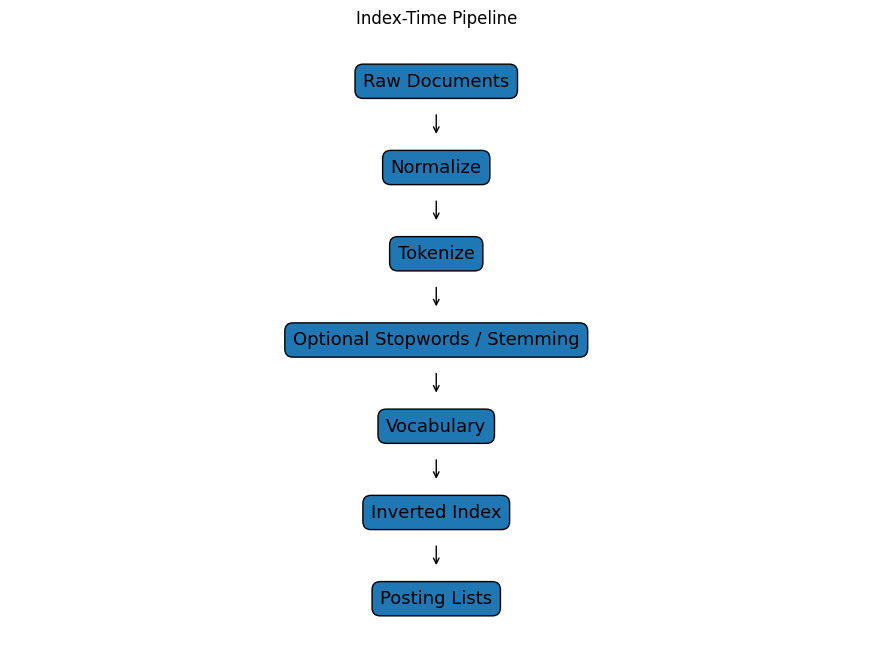

In [43]:
fig, ax = plt.subplots(figsize=(11, 8))
ax.axis("off")

steps = [
    (0.92, "Raw Documents"),
    (0.78, "Normalize"),
    (0.64, "Tokenize"),
    (0.50, "Optional Stopwords / Stemming"),
    (0.36, "Vocabulary"),
    (0.22, "Inverted Index"),
    (0.08, "Posting Lists")
]

for i, (y, label) in enumerate(steps):
    ax.text(
        0.5, y, label,
        ha="center", va="center",
        fontsize=13,
        bbox=dict(boxstyle="round,pad=0.45")
    )

    if i < len(steps) - 1:
        next_y = steps[i+1][0]
        ax.annotate(
            "",
            xy=(0.5, next_y + 0.05),
            xytext=(0.5, y - 0.05),
            arrowprops=dict(arrowstyle="->")
        )

plt.title("Index-Time Pipeline")
plt.show()

# 21. Query-Time Pipeline

After the index exists:

```text
USER QUERY
   ↓
Normalize / tokenize
   ↓
Dictionary lookup
   ↓
Posting lists
   ↓
Candidate documents
   ↓
Score / rank
   ↓
Top-K
```

The expensive document analysis happened earlier.

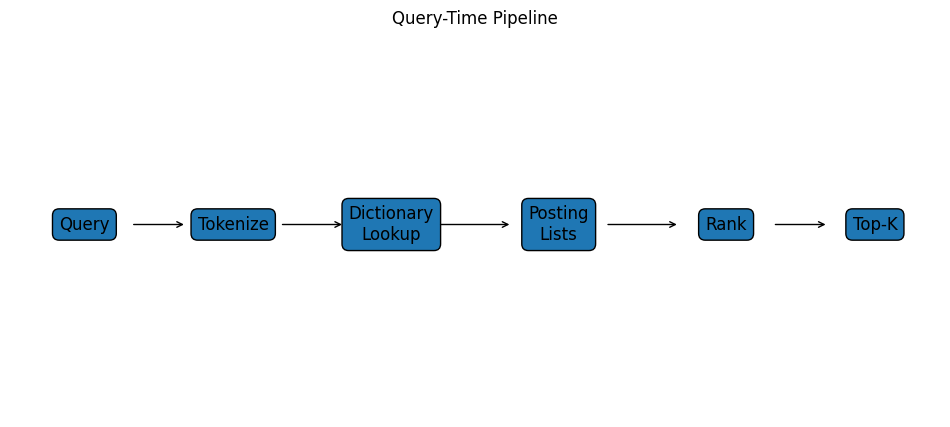

In [44]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")

labels = [
    (0.08, "Query"),
    (0.24, "Tokenize"),
    (0.41, "Dictionary\nLookup"),
    (0.59, "Posting\nLists"),
    (0.77, "Rank"),
    (0.93, "Top-K")
]

for x, label in labels:
    ax.text(
        x, 0.5, label,
        ha="center", va="center",
        fontsize=12,
        bbox=dict(boxstyle="round,pad=0.4")
    )

for i in range(len(labels)-1):
    ax.annotate(
        "",
        xy=(labels[i+1][0]-0.05, 0.5),
        xytext=(labels[i][0]+0.05, 0.5),
        arrowprops=dict(arrowstyle="->")
    )

plt.title("Query-Time Pipeline")
plt.show()

# 22. Index Time vs Query Time

### Index time

Happens before users search.

```text
documents
→ analyze
→ build index
```

### Query time

Happens when a user searches.

```text
query
→ lookup
→ ranking
```

Search engines spend more work up front so queries can be fast.

# 23. Sorted Posting Lists

Real posting lists are often sorted by document ID.

Example:

```text
cat  → [1, 3, 8, 10]
eats → [2, 3, 7, 8]
```

To compute AND, we can move through both lists with two pointers.

In [45]:
list_a = [1, 3, 8, 10]
list_b = [2, 3, 7, 8]

print("A:", list_a)
print("B:", list_b)

A: [1, 3, 8, 10]
B: [2, 3, 7, 8]


In [46]:
def intersect_sorted(a, b):
    i = 0
    j = 0
    result = []

    while (
        i < len(a)
        and j < len(b)
    ):
        print(
            f"\ni={i}, a[i]={a[i]} | "
            f"j={j}, b[j]={b[j]}"
        )

        if a[i] == b[j]:
            print("Equal → add")
            result.append(a[i])
            i += 1
            j += 1

        elif a[i] < b[j]:
            print("a is smaller → advance i")
            i += 1

        else:
            print("b is smaller → advance j")
            j += 1

    print("\nIntersection:")
    print(result)

    return result


intersect_sorted(
    list_a,
    list_b
)


i=0, a[i]=1 | j=0, b[j]=2
a is smaller → advance i

i=1, a[i]=3 | j=0, b[j]=2
b is smaller → advance j

i=1, a[i]=3 | j=1, b[j]=3
Equal → add

i=2, a[i]=8 | j=2, b[j]=7
b is smaller → advance j

i=2, a[i]=8 | j=3, b[j]=8
Equal → add

Intersection:
[3, 8]


[3, 8]

# 24. Candidate Retrieval vs Ranking

The inverted index tells us:

```text
which documents contain query terms
```

But if many documents match, we still need ranking.

That is where:

```text
TF-IDF
BM25
```

come in.

Pipeline:

```text
Inverted Index
      ↓
Candidate Documents
      ↓
Scoring
      ↓
Ranking
      ↓
Top-K
```

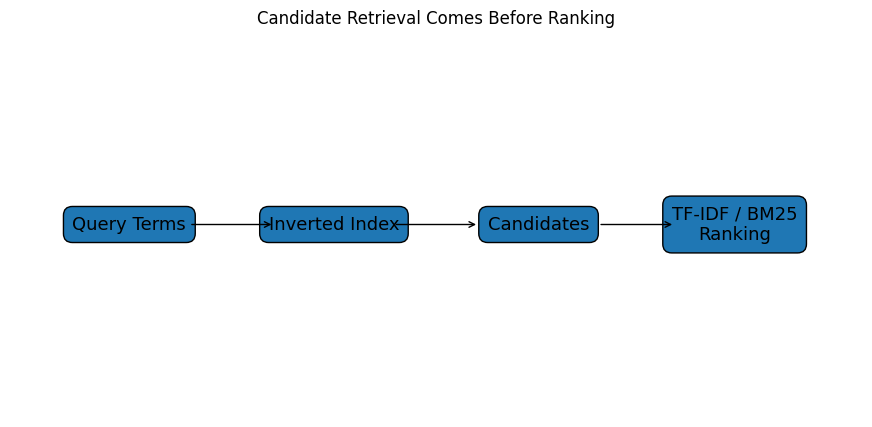

In [47]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")

steps = [
    (0.14, "Query Terms"),
    (0.38, "Inverted Index"),
    (0.62, "Candidates"),
    (0.85, "TF-IDF / BM25\nRanking")
]

for x, label in steps:
    ax.text(
        x, 0.5, label,
        ha="center", va="center",
        fontsize=13,
        bbox=dict(boxstyle="round,pad=0.5")
    )

for i in range(len(steps)-1):
    ax.annotate(
        "",
        xy=(steps[i+1][0]-0.07, 0.5),
        xytext=(steps[i][0]+0.07, 0.5),
        arrowprops=dict(arrowstyle="->")
    )

plt.title("Candidate Retrieval Comes Before Ranking")
plt.show()

# 25. Why This Matters for BM25

BM25 needs:

```text
term frequency
document frequency
document length
average document length
```

An inverted index can efficiently provide much of this information.

So:

```text
Inverted Index
     ↓
Posting Lists
     ↓
TF + DF statistics
     ↓
BM25 scoring
```

This chapter is the foundation for the BM25 chapter.

# 26. Inverted Index vs Vector Index

Hybrid Search commonly uses two different index families.

### Lexical side

```text
query terms
 ↓
inverted index
 ↓
posting lists
```

### Semantic side

```text
query
 ↓
embedding
 ↓
vector index
 ↓
nearest vectors
```

Then Hybrid Search combines the results.

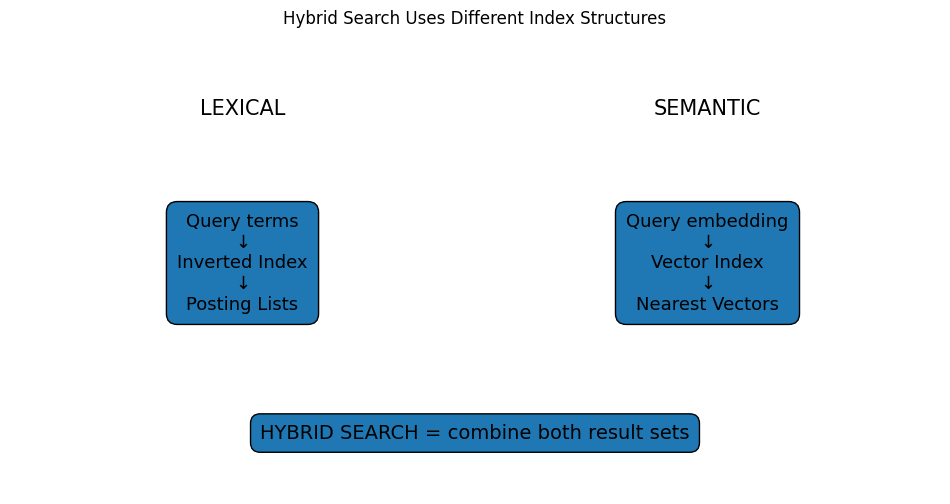

In [48]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

ax.text(0.25, 0.82, "LEXICAL", ha="center", fontsize=15)
ax.text(
    0.25, 0.50,
    "Query terms\n↓\nInverted Index\n↓\nPosting Lists",
    ha="center", va="center",
    fontsize=13,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.text(0.75, 0.82, "SEMANTIC", ha="center", fontsize=15)
ax.text(
    0.75, 0.50,
    "Query embedding\n↓\nVector Index\n↓\nNearest Vectors",
    ha="center", va="center",
    fontsize=13,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.text(
    0.5, 0.12,
    "HYBRID SEARCH = combine both result sets",
    ha="center", fontsize=14,
    bbox=dict(boxstyle="round,pad=0.5")
)

plt.title("Hybrid Search Uses Different Index Structures")
plt.show()

# 27. Common Misconceptions

### "The inverted index stores the full document for every term."

Usually no.

It stores compact references such as document IDs and optional statistics.

### "An inverted index automatically ranks documents."

Not necessarily.

It enables fast lookup. Ranking is another stage.

### "Vocabulary and posting list mean the same thing."

No.

```text
Vocabulary = unique terms
Posting list = documents for one term
```

### "Normal posting lists are enough for phrase search."

No.

Phrase search usually needs positions.

# 28. Debugging an Inverted Index

If lexical search behaves strangely, inspect:

```text
1. Was the document indexed?
2. Did tokenization create the expected term?
3. Did lowercasing change it?
4. Was it removed as a stopword?
5. Did stemming alter it?
6. Is the posting list correct?
7. Did Boolean logic filter it out?
8. Did ranking push it too low?
```

In [49]:
def debug_term(term, docs, index):
    normalized = term.lower()

    print("=" * 80)
    print("INDEX DEBUG")
    print("=" * 80)

    print("\nTerm:", term)
    print("Normalized:", normalized)

    print("\nIndex posting list:")
    print(index.get(normalized, []))

    print("\nManual check:")

    for doc_id, text in docs.items():
        tokens = tokenize(text)

        print(
            f"{doc_id}: "
            f"contains={normalized in tokens} | "
            f"tokens={tokens}"
        )


debug_term(
    "cat",
    documents,
    inverted_index
)

INDEX DEBUG

Term: cat
Normalized: cat

Index posting list:
['D1', 'D3']

Manual check:
D1: contains=True | tokens=['cat', 'drinks', 'milk']
D2: contains=False | tokens=['dog', 'eats', 'food']
D3: contains=True | tokens=['cat', 'eats', 'fish']
D4: contains=False | tokens=['bird', 'eats', 'seeds']
D5: contains=False | tokens=['dog', 'drinks', 'water']


# CHECKPOINT 4

Explain:

1. Why sorted posting lists are useful.
2. Difference between index time and query time.
3. Why inverted index is not itself a ranking algorithm.
4. How BM25 uses information from the index.
5. Difference between inverted index and vector index.

# 29. Interview Questions

### What is an inverted index?

A mapping from terms to documents containing those terms.

```text
cat → [D1, D3]
```

### Why is it called inverted?

Because:

```text
document → terms
```

is reversed into:

```text
term → documents
```

### What is a posting list?

The list of postings for one term. A posting may include document ID, frequency, positions and other metadata.

### What is TF?

How many times a term appears inside a specific document.

### What is DF?

How many documents contain a term.

### Why are inverted indexes fast?

They avoid scanning the entire corpus for each query and directly retrieve matching document references.

### Why do phrase queries need positions?

Because knowing both words exist is not enough; we need their order and adjacency.

### How does BM25 use the index?

It uses term statistics and candidate documents from the lexical index to calculate relevance scores.

# 30. Interview Scenarios

### Scenario 1

```text
red apple
```

Document:

```text
red sweet apple
```

Does exact phrase search match?

**No**, because the terms are not adjacent.

### Scenario 2

The word exists in the original document but search returns nothing.

Inspect:

```text
tokenization
normalization
stopwords
stemming
index construction
```

### Scenario 3

```text
cat  → [1, 3, 8]
eats → [2, 3, 8]
```

`cat AND eats` returns:

```text
[3, 8]
```

### Scenario 4

Why does Hybrid Search need an inverted index and vector index?

```text
inverted index → lexical evidence
vector index   → semantic evidence
```

# 31. One-Page Revision Map

```text
RAW DOCUMENTS
      │
      ▼
NORMALIZATION
      │
      ▼
TOKENIZATION
      │
      ▼
VOCABULARY
      │
      ▼
INVERTED INDEX
      │
      ├── cat  → [D1, D3]
      ├── dog  → [D2, D5]
      └── eats → [D2, D3, D4]
               │
               ▼
          POSTING LISTS
               │
       ┌───────┴────────┐
       ▼                ▼
Boolean Search      Ranking
AND / OR            TF-IDF / BM25
       │                │
       └───────┬────────┘
               ▼
             Top-K
```

Key definitions:

```text
TF = occurrences inside one document

DF = number of documents containing term

Positions = where term occurs in a document
```

# 32. Practice Tasks

### Task 1

Build an inverted index for:

```text
D1: apple banana mango
D2: banana orange
D3: apple orange grape
D4: mango grape
```

### Task 2

Search:

```text
apple AND orange
```

Expected:

```text
D3
```

### Task 3

Search:

```text
banana OR grape
```

### Task 4

Create:

```text
D1: apple apple apple banana
```

Store TF inside the posting.

### Task 5

Create positional indexes for:

```text
red apple
green apple
red sweet apple
```

Search exact phrase:

```text
red apple
```

### Task 6

Compare index terms before and after stopword removal.

### Task 7

For 10 simple documents, manually compute TF and DF for three terms.

# 33. Final Takeaways

Remember these ten points:

1. Naive search scans documents; indexed search performs direct lookups.
2. Forward index maps `document → terms`.
3. Inverted index maps `term → documents`.
4. Vocabulary contains unique searchable terms.
5. Posting lists store matching document references.
6. TF counts occurrences inside one document.
7. DF counts documents containing the term.
8. Positional indexes enable exact phrase search.
9. Tokenization and normalization strongly affect retrieval.
10. Inverted indexes are the foundation of TF-IDF, BM25 and the lexical side of Hybrid Search.

---

# Next Chapter — Chapter 4: TF-IDF

Next we answer:

> Why should rare terms matter more than common terms?

We will cover:

```text
Term Frequency
Document Frequency
Inverse Document Frequency
TF-IDF formula
manual calculations
from-scratch implementation
visualizations
limitations
why BM25 improves on TF-IDF
```